# An interview of a sample of patients: TMLE with sampling weights

## At a glance

A hospital program offered transition navigation to some patients going home. On day 30 a
structured interview scores each patient's daily functioning, but interviews are costly, so a
survey firm interviewed a sample of discharges and picked high-risk patients more often. Would offering
navigation to every discharged patient raise the average score, counting the patients who were
never interviewed?

Offering navigation to everyone would raise the average score by 0.997 points (95% confidence
interval 0.906 to 1.086), with most of the gain among high-risk patients. An analysis that ignores
how the sample was drawn gives 1.489, the effect among patients like those interviewed, who are
riskier than average and gain more.

The answer rests above all on two things the data cannot check: the chance of an interview depended only on
the recorded discharge risk, and nothing unrecorded drove both the offer and the score. The data
are simulated, so we know the true effect (1.000).

## The question

Discharge teams chose who got the navigation offer, guided by discharge risk and age. An
outside survey firm then picked each discharge for an interview with a chance between 0.15 and
0.90 that rises with discharge risk, and sends the program only the interviewed patients' records,
each with its chance. The program's sponsor asks how much the average day-30
score would change if every patient discharged in the period got the offer, compared with no one. This is the average
treatment effect (ATE) over every discharge, interviewed or not.

```text
  W ─────────────────┐
  │                  ▼
  ├──────▶ A ──────▶ Y
  │
  └──────▶ S          only rows with S = 1 reach the analyst

  W  = discharge_risk, age (recorded before the offer)
  A  = transition_navigation (the offer)
  Y  = function_score (the day-30 interview score)
  S  = interviewed; its chance depends on discharge_risk only
  not drawn: an unrecorded cause of A and Y, and any arrow from A or Y to S
```

The graph shows what we assume causes what, and the analysis rests on what it leaves out: no
unrecorded factor drives both the offer and the score, and neither the offer nor the score changed
the chance of an interview, which the firm set from discharge risk alone.

## The data

Every fit sets its seeds, so a rerun prints the same numbers.

In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression

import cleverly

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
print("cleverly", cleverly.__version__)

cleverly 0.2.8


Another version of `cleverly` can print slightly different numbers. This page needs pandas and matplotlib: `pip install "cleverly[all]"`.

`make_biased_sample` draws 8,000 simulated discharges, keeps the ones picked for an interview,
and returns the true effects, which real data never give.

In [2]:
from cleverly.datasets import make_biased_sample, sampling_probability

program_names = {
    "Y": "function_score",
    "A": "transition_navigation",
    "W1": "discharge_risk",
    "W2": "age",
}
# With your own data, load the interviewed patients here, such as frame = pd.read_csv(...), with
# each patient's chance of being picked for the interview, or the weight the survey team gives.
# Real data have no `truth`, so drop every line that uses it.
frame, truth = make_biased_sample(n_population=8_000, seed=22)
frame = frame.rename(columns=program_names)
frame["high_risk"] = (frame["discharge_risk"] > 0).astype(float)
print("rows and columns:", frame.shape)
print(list(frame.columns))
print(frame.head().round(3))
print()
chance = frame["sampling_prob"]
print(f"chance of an interview: {chance.min():.2f} to {chance.max():.2f}")
total = frame["sampling_weight"].sum()
print(f"sum of the weights:     {total:,.0f} (discharges in the period: 8,000)")

# Simulated data only. The simulation gives one patient an effect of 1 + 1.2 * discharge_risk,
# and discharge risk is standard normal over every discharge. Averaging that effect over a fine
# grid of risks, with or without each risk's interview chance, gives the true effects.
risk = np.linspace(-8.0, 8.0, 160_001)
density = np.exp(-(risk**2) / 2)
interviewed = density * sampling_probability(risk)


def true_effect(mass, rows=True):
    mass = mass * rows
    return float(np.sum((1 + 1.2 * risk) * mass) / np.sum(mass))


print(f"true effect over every discharge:          {true_effect(density):.3f}")
print(f"true effect over patients like those interviewed: {true_effect(interviewed):.3f}")

rows and columns: (3672, 7)
['function_score', 'transition_navigation', 'discharge_risk', 'age', 'sampling_prob', 'sampling_weight', 'high_risk']
   function_score  transition_navigation  discharge_risk    age  sampling_prob  sampling_weight  high_risk
0           2.043                    0.0           1.447 -1.601          0.751            1.332        1.0
1           4.032                    1.0           0.944  1.262          0.657            1.522        1.0
2           7.511                    1.0           2.156  0.892          0.851            1.176        1.0
3           6.604                    1.0           1.838 -0.578          0.811            1.234        1.0
4           4.917                    0.0           1.189  1.423          0.705            1.419        1.0

chance of an interview: 0.15 to 0.90
sum of the weights:     7,955 (discharges in the period: 8,000)
true effect over every discharge:          1.000
true effect over patients like those interviewed: 1.487


Each row is one interviewed patient: the score, the offer (1 or 0), discharge risk and age on a
standardized scale, the chance that this patient was picked (`sampling_prob`), and its inverse,
the sampling weight. A patient picked with a chance of one in four has weight 4: they stand for
themselves and three similar patients who were not interviewed, so the weights add up to about
the 8,000 discharges. `high_risk` marks a discharge risk above 0.

The true effect is 1.000 over every discharge and 1.487 over patients like those interviewed,
because navigation adds more for riskier patients and the sample holds more of them.

## Why a simple comparison misleads

The weighted mean of a column is its mean over every discharge, as the weights describe them.

In [3]:
covariates = ["discharge_risk", "age"]
sample_mean = frame[covariates].mean()
weighted_mean = frame[covariates].apply(
    lambda column: np.average(column, weights=frame["sampling_weight"])
)
print("mean characteristic:")
print(
    pd.DataFrame({"interviewed": sample_mean, "weighted to all discharges": weighted_mean}).round(3)
)
print()
treated = frame["transition_navigation"] == 1
raw_difference = (
    frame.loc[treated, "function_score"].mean() - frame.loc[~treated, "function_score"].mean()
)
print(f"difference in mean score, offered minus not offered: {raw_difference:.3f}")
print(f"true effect over every discharge:                    {truth['ate']:.3f}")

mean characteristic:
                interviewed  weighted to all discharges
discharge_risk        0.410                       0.016
age                  -0.004                      -0.007

difference in mean score, offered minus not offered: 1.912
true effect over every discharge:                    1.000


The interviewed patients have a mean discharge risk of 0.410, against 0.016 over every discharge
once weighted, so the sample leans toward high-risk patients. The raw difference in mean score,
1.912, is far from the true 1.000: riskier patients got the offer more often and score
differently, and the sample overrepresents the patients who gain most.

## Set up the analysis

Describe the study (`StudyProtocol`). This step is optional and does not change the estimate, so you can skip it on a first
pass: it records what the estimate means, and every result fitted from the study carries it. The code
edits four fields of this program's description to fit the interview sample.

In [4]:
from dataclasses import replace

from cleverly.datasets import navigation_protocol

# For your own study, build the description with cleverly.StudyProtocol(...), naming the
# population, treatment, outcome and the reasons behind each assumption. With a sampled
# measurement, say in target_population who the sample stands for, and give the sampling design
# in assumption_rationale, as below.
program = navigation_protocol()
protocol = replace(
    program,
    target_population=(
        f"{program.target_population}; a sample of them is interviewed, with known chances "
        "that depend on discharge risk"
    ),
    outcome=(
        "Functional-status score from a structured interview on day 30, in points "
        "(higher is better)"
    ),
    # The program's rules for events after the offer name its usual score; this page's is the
    # interview score.
    intercurrent_event_handling=tuple(
        rule.replace("transition score", "interview score")
        for rule in program.intercurrent_event_handling
    ),
    assumption_rationale=(
        *program.assumption_rationale[:1],
        "Who is interviewed depends only on the recorded discharge risk, through a chance that "
        "the survey firm sets and records for every interviewed patient",
        *program.assumption_rationale[1:],
    ),
)
print("\n".join(protocol.summary_lines()))

Population: Adults with a discharge-home order at a participating hospital during the enrollment period; a sample of them is interviewed, with known chances that depend on discharge risk
Eligibility: Age 18 years or older; Discharge home ordered at a participating hospital
Follow-up starts: Discharge-home order, after baseline measurement and before the navigation offer
Strategies: Offer standard transition navigation; Provide usual discharge support
Versions: Bedside transition plan and two scheduled navigator contacts within 30 days; No access to the transition-navigation offer
Outcome: Functional-status score from a structured interview on day 30, in points (higher is better)
Horizon: 30 days after discharge
Intercurrent events: Use the interview score regardless of readmission; Analyze the offer regardless of completed contacts; The protocol scores death before day 30 as the worst interview score (composite strategy)
Interference unit: Individual patient
Rationale: The recorded bas

"Intercurrent events" are the rules for events
after the offer that change what the score means, such as a death before day 30, which the program
counts as the worst score; these simulated data have no deaths. "Interference unit" is the unit
whose offer can affect only its own score. The population is still every
discharged patient, not only those interviewed.

Next, name the outcome, the treatment, the characteristics to adjust for, the weight column
(`weights="sampling_weight"`), and the quantity to estimate (`ATE(reference=0)`).
`study.identify(...)` lists what must be true for the answer to be causal.

In [5]:
from cleverly import ATE, CausalStudy, PointTreatment

# For your own data, change the column names and the `covariates` list, and name your weight
# column. Do not adjust for the chance or the weight: they set the population, not a cause.
study = CausalStudy(
    frame,
    design=PointTreatment(
        outcome="function_score",
        treatment="transition_navigation",
        adjustment=tuple(covariates),
        weights="sampling_weight",
    ),
    protocol=protocol,
)
effect = study.identify(ATE(reference=0))
print(effect.summary())

                            Causal question (ate)
Question:      average effect of        Rows:                            3,672
               transition_navigation    Answered by:  adjusting for covariates
               on function_score (1
               compared with 0)
Outcome:       function_score
               (continuous)
Treatment:     transition_navigation
               (levels 0, 1)
Adjusted for:  discharge_risk, age
Conditions the answer rests on
condition                checkable   what it says
------------------------------------------------------------------------------
well-defined treatment   no          Each unit's observed outcome is the
                                     outcome it would have had under the
                                     treatment it actually received. This
                                     needs the treatment to be well defined:
                                     every way of getting the same level has
                               

The four conditions are the usual ones for a treatment given once. A well-defined treatment (an
offer always means the same plan, also called consistency) and no interference (one patient's
offer does not change another's score) rest on the
[shared study design](index.md#the-shared-study-design). The data cannot check no hidden
confounding, and "Check the fit" probes overlap. The methods table lists the methods that can
answer this question; this page uses TMLE.

The weights add one more condition, about how the sample was drawn: among patients with the same
recorded characteristics, those interviewed are like those who were not. Here that holds because
the firm picked patients by discharge risk alone. The chance and the weight stay out of
`adjustment` because they describe whom each row stands for, not a cause of the offer or the
score, and the chance is a function of discharge risk, which is already adjusted for.

## Estimate the effect

The method, targeted maximum likelihood estimation (TMLE), fits an outcome model and a treatment
model, then applies a correction step that weights each patient by one over their predicted chance
of the offer they got. With `weights=`, every step also weights each patient by their sampling
weight, so the sample stands in for every discharge.

- `outcome_learner`: a linear regression of the score on the offer and the characteristics.
- `treatment_learner`: a logistic regression of the offer on the characteristics.
- `CrossFitting(enabled=False)`: both models are simple, so they are trained on every patient.
  Flexible models need out-of-fold predictions, and with them `cleverly` asks for the lowest and
  highest possible score (`q_bounds`), which this simulated score lacks.
- `Targeting(fluctuation="linear")`: the correction step shifts the predicted scores directly.
  Keep it for a weighted continuous score: it is the setting tested for that case.
- `Runtime(random_state=22, n_jobs=1)`: a fixed seed.

In [6]:
from cleverly import CrossFitting, ModelSpec, Runtime, Targeting, TMLEMethod

# For your own data, swap in your learners. With flexible learners, use out-of-fold predictions
# (CrossFitting(n_folds=5)) and declare the outcome's known range with Targeting(q_bounds=...).
# A continuous outcome with no known range keeps simple models fitted on every row, as here.
method = TMLEMethod(
    models=ModelSpec(
        outcome_learner=LinearRegression(),
        treatment_learner=LogisticRegression(max_iter=1000, random_state=22),
    ),
    cross_fitting=CrossFitting(enabled=False),
    targeting=Targeting(fluctuation="linear"),
    runtime=Runtime(random_state=22, n_jobs=1),
)
weighted = effect.estimate(method=method)
print(weighted.summary())
print()
print(f"true effect over every discharge: {truth['ate']:.3f}")

                            Effect estimate (TMLE)
Question:      average effect of        Rows:                            3,672
               transition_navigation    Treated share (weighted):        0.501
               on function_score (1     Out-of-fold predictions:            no
               compared with 0)         Outcome model:       linear regression
Outcome:       function_score           Treatment model:   logistic regression
               (continuous)             Probability limits:  [0.01142, 0.9886]
Adjusted for:  discharge_risk, age
Method:        targeted maximum
               likelihood (TMLE)
Weights:       sampling_weight;
               effective sample size
               2,993
      estimate   std. error           95% CI    p-value
------------------------------------------------------------------------------
ate      0.997        0.045   [0.906, 1.086]    <0.0001
Notes:
[1] The interval of ate is widened on the side where a skewed outcome makes
    misses 

The answer is in the bottom table: 0.997 points, with an interval from 0.906 to 1.086 that
contains the true 1.000. The summary's Weights line says the weights make the 3,672 interviewed
patients count like 2,993 equally weighted ones, so weighting costs some precision.

:::{dropdown} Details: the weighted target, the models, and a repeated-draw check
With weights $w = 1/\pi(W)$, the fit estimates the ATE under the law $w\,dP_S / E_S[w]$, where
$P_S$ is the law of the interviewed patients. Because the interview chance $\pi$ depends only on
the recorded discharge risk, that law is the law of every discharge, so the target is the
population ATE ([point-treatment TMLE](../technical-reference/point-treatment-tmle.md), section
"Weights, strata, and clusters").

In these simulated data the logistic treatment model has the true form, and the linear outcome
model does not: it misses that the effect grows with discharge risk. The estimate stays on target
because the treatment model is right. With a correct parametric treatment model, the influence-curve interval is valid or slightly wide even when the outcome model is
wrong. With flexible learners, both models must be estimated well enough: the product of their
errors must shrink faster than $1/\sqrt{n}$. The interval treats the interviewed patients as
independent draws, and it does not use survey design strata or a finite-population correction.

A simulation we ran for this page (script
`reviews/notebook-review/probes/sampling-weights/probe.py`) repeats this fit on 500 draws of the
same simulated data. The interval contained the true effect on 476 of them, and the spread of
the estimates matched the standard error (ratio 0.993).
:::

## What an unweighted analysis answers

A common shortcut fits the same models without the weights, with the default correction step that
the simulation studies of unweighted fits measured. On these data the two correction steps give the same estimate to three decimals, so the gap
below comes from the weights. It answers a different question.

weighted    0.997  95% CI (0.906, 1.086)  supported
            covers all=True  covers interviewed=False
unweighted  1.489  95% CI (1.411, 1.567)  supported
            covers all=False  covers interviewed=True
gap between the estimates: 0.492, or 8.2 combined standard errors


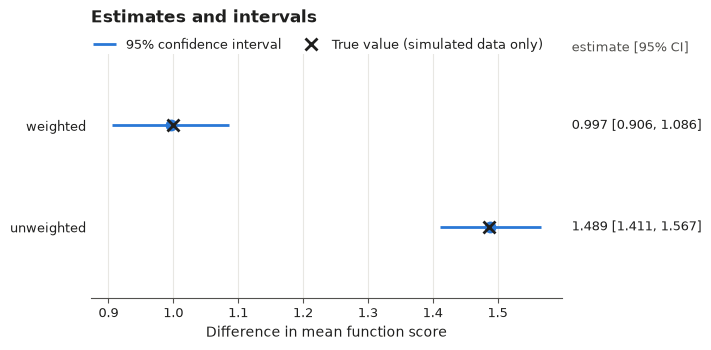

In [7]:
from cleverly import plotting

targets = {"all": true_effect(density), "interviewed": true_effect(interviewed)}


def show(label, result):
    point = result["ate"]
    low, high = point.ci
    hits = "  ".join(f"covers {name}={low <= value <= high}" for name, value in targets.items())
    print(f"{label:11s} {point.psi:.3f}  95% CI ({low:.3f}, {high:.3f})  {point.support.label}")
    print(f"{'':11s} {hits}")


unweighted_design = PointTreatment(
    outcome="function_score", treatment="transition_navigation", adjustment=tuple(covariates)
)
# The default correction step, the setting the unweighted simulation studies measured. No study
# description: without the weights, the answer is about the interviewed patients.
plain_method = replace(method, targeting=Targeting())
unweighted = (
    CausalStudy(frame, design=unweighted_design)
    .identify(ATE(reference=0))
    .estimate(method=plain_method)
)
show("weighted", weighted)
show("unweighted", unweighted)
gap = unweighted["ate"].psi - weighted["ate"].psi
joint_se = np.hypot(unweighted["ate"].std_error, weighted["ate"].std_error)
print(f"gap between the estimates: {gap:.3f}, or {gap / joint_se:.1f} combined standard errors")
# Simulated data only: each fit's own true target, drawn as a cross on its row.
comparison_fig = plotting.forest(
    weighted,
    unweighted,
    labels=["weighted", "unweighted"],
    truth={"weighted": targets["all"], "unweighted": targets["interviewed"]},
)

The last column is the support label: `supported` when a simulation study covers this kind of
fit, `experimental` when none does. The unweighted fit gives 1.489. Its interval contains its own
target, the effect over patients like those interviewed (1.487, the cross on its row), and misses
the effect over every discharge, 1.000.
The two targets agree when the characteristics that drive the interview chance do not change the
size of the effect, but here discharge risk does both.

:::{dropdown} Details: repeated draws
The script `reviews/notebook-review/probes/sampling-weights/probe.py` repeats both fits on 500
draws. The unweighted interval contained the effect over every discharge on 0 of them, and the
effect over patients like those interviewed on 470.
:::

## Effects for high- and low-risk patients

`strata=("high_risk",)` adds one row for each group of patients. The code fits the groups with and
without the weights, and prints the true effect each fit aims at: the group over every discharge,
or the group among patients like those interviewed.

In [8]:
def by_group(weights, group_method):
    design = PointTreatment(
        outcome="function_score",
        treatment="transition_navigation",
        adjustment=(*covariates, "high_risk"),
        strata=("high_risk",),
        weights=weights,
    )
    return (
        CausalStudy(frame, design=design).identify(ATE(reference=0)).estimate(method=group_method)
    )


fits = {"weighted": by_group("sampling_weight", method), "unweighted": by_group(None, plain_method)}
rows = []
for group, label, side in ((1.0, "high risk", risk > 0), (0.0, "low risk", risk <= 0)):
    # Each fit's own target: every discharge in the group, or patients like those interviewed.
    group_targets = {
        "weighted": true_effect(density, side),
        "unweighted": true_effect(interviewed, side),
    }
    for name, fit in fits.items():
        point = fit[f"ate[high_risk={group}]"]
        rows.append(
            {
                "group": label,
                "fit": name,
                "estimate": point.psi,
                "CI low": point.ci[0],
                "CI high": point.ci[1],
                "true target": group_targets[name],
                "support": point.support.label,
            }
        )
print(pd.DataFrame(rows).round(3).to_string(index=False))
print()
share = np.average(frame["high_risk"], weights=frame["sampling_weight"])
print(f"high-risk share, weighted to all discharges: {share:.3f}")
print(f"high-risk share among the interviewed:       {frame['high_risk'].mean():.3f}")
print("support of the overall row of the weighted fit:", fits["weighted"]["ate"].support.label)

    group        fit  estimate  CI low  CI high  true target      support
high risk   weighted     2.005   1.919    2.090        1.957 experimental
high risk unweighted     2.135   2.049    2.222        2.089 experimental
 low risk   weighted     0.012  -0.121    0.143        0.043 experimental
 low risk unweighted     0.208   0.085    0.331        0.254 experimental

high-risk share, weighted to all discharges: 0.502
high-risk share among the interviewed:       0.670
support of the overall row of the weighted fit: experimental


Navigation adds about 2 points for high-risk patients and nearly nothing for low-risk ones: the
weighted estimates are 2.005 and 0.012, and each interval contains its group's true effect. The
weights still matter inside a group, because the interview chance rises with risk inside each
group too, so both unweighted estimates sit higher, near the effects among patients like those
interviewed.

All these rows read `experimental` (see "How we know the method works"), and so does the overall
row of the grouped fit, which is why the main answer comes from the fit without groups. A group
column must be an adjustment column, because each row compares patients within the group. These
groups only report effects; the interval does not use them as survey strata.

## Check the fit

The answer predicts every patient's score under both options, so every kind of patient needs a
real chance of each option (overlap). The correction step divides by those chances, and the fit
caps them at the "Probability limits" of the summary so that no patient's correction weight grows
without limit. The models the fit needs on the way to the answer, here the outcome and treatment
models, are its `nuisance_models`.

In [9]:
assessment = weighted.assess()
support = assessment.report("support")
nuisance = assessment.report("nuisance_models")  # the outcome and treatment models
weights_report = weighted.data.weight_report()
attention = tuple(item.name for item in assessment.attention)
print("checks that need attention:", attention or "none")
print()
print(f"smallest fitted chance of either option: {support.truncated['most_extreme']:.3f}")
print(f"share of patients at the caps:           {support.truncated['fraction']:.3f}")
print(f"largest sampling weight:                 {frame['sampling_weight'].max():.2f}")
print(f"interviewed patients:                    {len(frame):,}")
print(f"counted as equally weighted rows:        {weights_report.effective_n:,.0f}")
models = {model.name: model.metrics for model in nuisance.models}
print(f"outcome model R^2: {models['outcome']['r2']:.2f}")
print(nuisance.summary().reading)

checks that need attention: none

smallest fitted chance of either option: 0.140
share of patients at the caps:           0.000
largest sampling weight:                 6.67
interviewed patients:                    3,672
counted as equally weighted rows:        2,993
outcome model R^2: 0.71
The models show no problem these metrics can detect.


Nothing needs attention, and no patient reached a cap: the smallest fitted chance of either
option is 0.140. Chances near 0 or 1, or many patients at the caps, would mean some patients have
no comparable patients under the other option. Both overlap numbers read the fitted treatment
model.

The largest sampling weight is 6.67, because the firm
never set an interview chance below 0.15. A few very large weights would make the answer rest on few patients. The
linear outcome model explains 71% of the score's variation, enough here because the treatment
model is correct. With your own data you cannot know that, so try a flexible outcome model too.

## What if a confounder is missing?

An unrecorded cause of both the offer and the score has two strengths, each a share from 0 to 1.
On the score side (`cf_y`), it is the share of the score's remaining variation it explains. On the
weight side (`cf_d`), it is how much it would change the one-over-chance weights of the correction
step. Each recorded characteristic serves as a yardstick: a confounder as strong as it gives, in the
worst case, a range the effect could lie in (`benchmark`, `omitted_confounding`). The code also searches for the weight-side
strength that would bring the range of the estimate down to zero.

robustness value:                  0.340
robustness value at the 95% limit: 0.316

a confounder as strong as discharge_risk:
  score-side strength, cf_y    1.000
  weight-side strength, cf_d   0.037
  range of the estimate        [0.531, 1.464]
  one-sided 95% limits         [0.451, 1.537]

a confounder as strong as age:
  score-side strength, cf_y    0.157
  weight-side strength, cf_d   0.025
  range of the estimate        [0.847, 1.147]
  one-sided 95% limits         [0.770, 1.221]



weight-side strength at which the range reaches zero, at cf_y = 1: 0.15


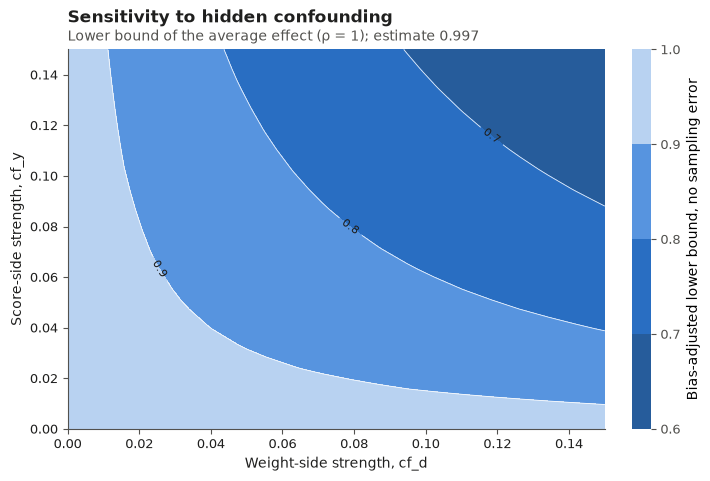

In [10]:
sensitivity = weighted.sensitivity
rv = sensitivity.robustness_value()
print(f"robustness value:                  {rv['rv']:.3f}")
print(f"robustness value at the 95% limit: {rv['rva']:.3f}")

# For your own data, benchmark against every recorded confounder.
benchmarks = {}
for covariate in covariates:
    record = sensitivity.benchmark(covariates=(covariate,))
    bound = sensitivity.omitted_confounding(benchmark=record)
    benchmarks[covariate] = (record, bound)
    print()
    print(f"a confounder as strong as {covariate}:")
    print(f"  score-side strength, cf_y    {record.cf_y:.3f}")
    print(f"  weight-side strength, cf_d   {record.cf_d:.3f}")
    print(f"  range of the estimate        [{bound.lower:.3f}, {bound.upper:.3f}]")
    print(f"  one-sided 95% limits         [{bound.ci_lower:.3f}, {bound.ci_upper:.3f}]")

# The weight-side strength at which the range of the estimate reaches zero, for a confounder
# that explains all of the remaining score variation (cf_y = 1), found by bisection.
low, high = 0.0, 0.99
for _ in range(40):
    middle = (low + high) / 2
    if sensitivity.omitted_confounding(cf_y=1.0, cf_d=middle).lower > 0:
        low = middle
    else:
        high = middle
tipping_cf_d = (low + high) / 2
print()
print(f"weight-side strength at which the range reaches zero, at cf_y = 1: {tipping_cf_d:.2f}")
confounding_fig = sensitivity.contour().plot(
    robustness=rv,
    benchmarks=[record for record, _ in benchmarks.values()],
    xlabel="Weight-side strength, cf_d",
    ylabel="Score-side strength, cf_y",
)

The robustness value is 0.340: a confounder weaker than that on both sides cannot push the
effect to zero, and one stronger on both sides can. A confounder as strong as age would leave the
effect between 0.847 and 1.147. Discharge risk drives most of the score, so a confounder as strong
as it sits at the top of the score side (`cf_y` of 1.000), yet its small weight-side strength still
leaves the effect between 0.531 and 1.464. At that top score-side strength, a weight-side strength
of 0.15 would bring the range down to zero, against 0.037 for discharge risk.

In the figure, the marked points are the recorded characteristics, and the bold line is where the
lower end of the range reaches zero. The values at the interval's limit (the 0.316 and
the one-sided limits) are descriptive: no simulation study checks them on a weighted fit or a continuous outcome. Only the
program staff can judge whether such a confounder exists.

:::{dropdown} Details: what the strengths mean
`cf_y` is the share of the outcome variation left after the fitted outcome model, which reads the
offer and the recorded characteristics, that a missing confounder explains. This outcome model
misses that the effect grows with discharge risk, so the bound at a given `cf_y` is wider than it
would be under the true regression. `cf_d` is the share of the second moment of
the Riesz representer that only the missing confounder adds. The bound uses `rho = 1`, the worst
case, and the observation-weighted means of both moments, so it bounds the weighted-population
effect. `benchmark()` refits without one covariate and reports gain statistics that serve as
proxies for these strengths. Without discharge risk the remaining outcome variance more than
doubles, so its `cf_y` clips to 1.
[Omitted-variable bounds](../technical-reference/validation-methods.md#omitted-variable-bounds-robustness-value-benchmark-and-contours)
defines each quantity.
:::

## What we can and can't conclude

For the program's sponsor: offering navigation to every discharged patient would raise the
average day-30 score by about 1.0 point (95% interval 0.906 to 1.086), counting the patients who
were never interviewed. The gain sits with high-risk patients, about 2 points, while low-risk
patients gain close to nothing; no simulation study has checked such group estimates with weights, so present them as a guide. The interval
covers sampling variation only.

The answer rests on conditions the data cannot check. The interview chance must be known and
depend only on recorded characteristics; here the firm set it from discharge risk. No unrecorded
factor may drive both the offer and the score; one as strong as discharge risk would not overturn
the answer. An offer must mean the same for everyone and not affect other patients.

This is not the effect among patients like those interviewed, which the unweighted fit estimates
at 1.489. The page shows one simulated sample with a known answer, which does not show how the
method performs in general.

## Go deeper

### How we know the method works

| section | simulation study | simulated data |
| --- | --- | --- |
| "Estimate the effect" | [learned weighted point-treatment TMLE](../technical-reference/method-evidence/learned-weighted-point-treatment-tmle.md), with linear and logistic models, and [weighted point-treatment TMLE](../technical-reference/method-evidence/weighted-point-treatment-tmle.md) for a yes-or-no outcome | other data, sampled by a covariate |
| "What an unweighted analysis answers" | [ordinary point-treatment TMLE](../technical-reference/method-evidence/canonical-point-treatment-tmle.md) | other data, unweighted, with a continuous outcome |
| "Effects for high- and low-risk patients" | [point-treatment TMLE with groups](../technical-reference/method-evidence/stratified-point-treatment-tmle.md) | other data, unweighted, with a yes-or-no outcome |
| "When some offer records are missing" | [missing outcomes and treatments](../technical-reference/method-evidence/observational-missing-data-dr-tmle.md) | other data, unweighted, with a yes-or-no outcome |
| "The same weights over two decisions", weighted | [cross-fitted weighted longitudinal TMLE](../technical-reference/method-evidence/cross-fitted-weighted-end-of-study-longitudinal-tmle.md) | the data of this lesson |
| "The same weights over two decisions", unweighted | [cross-fitted longitudinal TMLE](../technical-reference/method-evidence/cross-fitted-end-of-study-longitudinal-tmle.md) | other data, unweighted |

No study covers this page's simulated data, and none covers weights together with groups or with
missing offer records, which is why those rows read `experimental`. The weighted two-decision
study used the true offer and dropout mechanisms, while this lesson fits logistic models for them.
The simulation run for this page, a script under `reviews/notebook-review/probes/`, checks the
numbers this page quotes; it is not a validation of the method. The
[technical entry](../technical-reference/point-treatment-tmle.md#validation-issues-special-to-this-method)
lists the method's evidence and limits.

### Try to break the result

These checks change the data in a known way and refit 20 times each:

- `placebo` shuffles the offer, so the estimate should be about zero;
- `random_common_cause` adds a column of noise, so the estimate should barely move;
- `subset` refits on random 70% samples, so the estimates should spread as much as the standard
  error predicts for samples of that size.

In [11]:
from cleverly.validation import refute

refutation = refute(weighted, tests=("placebo", "subset", "random_common_cause"))
columns = ["test", "original", "refuted_mean", "refuted_sd", "expectation", "verdict"]
print(refutation.to_frame()[columns].round(3).to_string(index=False))

               test  original  refuted_mean  refuted_sd       expectation     verdict
            placebo     0.997        -0.014       0.033               ~ 0 descriptive
             subset     0.997         1.001       0.028 scatter ~ 0.02971 descriptive
random_common_cause     0.997         0.997       0.001          ~ 0.9971 descriptive


All three behave as expected: the shuffled offer gives an estimate near zero, the noise column
does not move it, and the 70% refits spread about as much as the standard error predicts. These
checks test the method, so they cannot detect a hidden confounder or a sample drawn on something
unrecorded. The `verdict` column reads `descriptive`: `cleverly` gives a pass or fail only when a
simulation study backs the check for this kind of fit. No study covers the noise-column check
at all, and the studies of the other two do not cover a fit like this one, with no out-of-fold
predictions and learners outside those studied.

### When some offer records are missing

Sometimes the record of who got the offer is lost for some patients. Dropping those patients
would change the population again. Instead, name a 0/1 column that is 1 where the offer was
recorded (`treatment_missingness=`), and give a model for who has a record
(`missingness_learner`). The code below hides about a quarter of the offer records in the
simulated data, more often for younger and for offered patients.

In [12]:
# Simulated data only: hide some offer records. A record is kept with a chance that rises with
# age (standardized) and is lower for offered patients. With your own data, the offer column
# holds NaN where it was not recorded, and a 0/1 column marks the rows where it was.
records = np.random.default_rng(23)
kept = 1 / (1 + np.exp(-(1.5 + 0.8 * frame["age"] - 0.7 * frame["transition_navigation"])))
patchy = frame.assign(offer_recorded=(records.random(len(frame)) < kept).astype(float))
patchy.loc[patchy["offer_recorded"] == 0, "transition_navigation"] = np.nan
print(f"share of offer records kept: {patchy['offer_recorded'].mean():.3f}")

patchy_design = PointTreatment(
    outcome="function_score",
    treatment="transition_navigation",
    adjustment=tuple(covariates),
    weights="sampling_weight",
    treatment_missingness="offer_recorded",
)
patchy_method = replace(
    method,
    models=replace(
        method.models, missingness_learner=LogisticRegression(max_iter=1000, random_state=22)
    ),
)
patchy_fit = (
    CausalStudy(patchy, design=patchy_design)
    .identify(ATE(reference=0))
    .estimate(method=patchy_method)
)
point = patchy_fit["ate"]
low, high = point.ci
print(f"estimate {point.psi:.3f}, 95% CI ({low:.3f}, {high:.3f}), support {point.support.label}")
print(f"true effect over every discharge: {truth['ate']:.3f}")

share of offer records kept: 0.728
estimate 0.980, 95% CI (0.870, 1.087), support experimental
true effect over every discharge: 1.000


The estimate, 0.980, stays near the true 1.000, and its interval contains it. For each option, the
fit uses the patients whose record shows that option, so the weights, the offer model and the
record model all enter the correction step. It needs two more conditions. The data cannot check
the first: given the recorded characteristics and the offer itself, whether the record survived
says nothing more about the score. The second is overlap for records: every kind of patient needs
a real chance of a kept record under each option. A missing offer also needs models fitted on
every patient, as here: `cleverly` refuses out-of-fold predictions with a missing treatment.

None of the three models is exact here. The record depends on the offer, so neither the offer model
nor the record model has the true form, and the linear outcome model misses that the effect grows
with discharge risk. The simulation run for this page found the interval contained the truth on
481 of 500 draws. The row reads `experimental`, because no study covers a missing offer with
weights and a continuous score. A missing offer supports the effect over everyone, but not the
effects among offered or not-offered patients (ATT and ATC)
([declaring your data](../user-guide/data-design.md), section "Missing outcomes and missing
treatments").

### The same weights over two decisions

The weights work the same way when the offer is decided twice. `make_longitudinal_weighted` keeps
each of 8,000 simulated patients with chance 0.3 or 0.9 by a baseline characteristic and gives the
weight `w`; its columns keep their generic names. The code estimates the chance of a yes-or-no
outcome under two plans, offer at both times and offer at neither, with and without the weights.

In [13]:
from cleverly import LongitudinalTreatment, RegimeMean
from cleverly.datasets import make_longitudinal_weighted

# Two offer decisions, A1 and A2, a yes-or-no outcome Y, baseline W1 and W2, a measure L2 between
# the decisions, dropout C1 and C2, and the sampling weight w (chances 0.3 and 0.9 by W1).
plans_frame, plans_truth = make_longitudinal_weighted(n=8_000, seed=22)
plans_method = TMLEMethod(
    models=ModelSpec(
        outcome_learner=LogisticRegression(max_iter=1000),
        # The first decision's step is fitted to the second step's predicted chances, a number
        # between 0 and 1, so it takes a regression.
        pseudo_learner=LinearRegression(),
        treatment_learner=LogisticRegression(max_iter=1000),
        censoring_learner=LogisticRegression(max_iter=1000),  # staying in follow-up (C1, C2)
    ),
    cross_fitting=CrossFitting(n_folds=5),
    runtime=Runtime(random_state=22, n_jobs=1),
)
plans = {"always": 1, "never": 0}
plan_rows = []
for label, plan_weights in (("weighted", "w"), ("unweighted", None)):
    design = LongitudinalTreatment(
        outcome="Y",
        treatment=("A1", "A2"),
        baseline=("W1", "W2"),
        time_varying=((), ("L2",)),  # L2 is measured before the second decision
        censoring=("C1", "C2"),
        weights=plan_weights,
    )
    plan_fit = (
        CausalStudy(plans_frame, design=design)
        .identify(RegimeMean(regimens=plans))
        .estimate(method=plans_method)
    )
    for plan in plans:
        point = plan_fit[f"ey_regimen[{plan}]"]
        true = plans_truth[f"ey_regimen[{plan}]"]
        plan_rows.append(
            {
                "fit": label,
                "plan": plan,
                "estimate": point.psi,
                "CI low": point.ci[0],
                "CI high": point.ci[1],
                "true": true,
                "covers": point.ci[0] <= true <= point.ci[1],
                "support": point.support.label,
            }
        )
print(f"rows kept from 8,000: {len(plans_frame):,}")
print(pd.DataFrame(plan_rows).round(3).to_string(index=False))

rows kept from 8,000: 4,755
       fit   plan  estimate  CI low  CI high  true  covers   support
  weighted always     0.777   0.751    0.802 0.780    True supported
  weighted  never     0.421   0.381    0.461 0.419    True supported
unweighted always     0.743   0.715    0.769 0.780   False supported
unweighted  never     0.374   0.344    0.405 0.419   False supported


With the weights, both plans' intervals contain their true chances (0.780 and 0.419). Without
them, both estimates are low and here both intervals miss, because the sample overrepresents patients
whose outcome is less likely; the simulation run for this page found the unweighted intervals
missing on most draws (55 and 29 of 500 covered). The plan chances are
the quantities to read here, because a sample that shifts both chances the same way can leave
their difference nearly unchanged. All four rows read `supported`.
[Longitudinal TMLE](../technical-reference/longitudinal-tmle.md) gives the conditions over time.

## Where to go next

When the program holds every discharge's record and only some scores are missing, analyze the
missing scores as missing outcomes instead of weighting the interviewed patients: the
[missing survey answers](survey-nonresponse.ipynb) example models who responds. The
[examples index](index.md) lists every example.

For this kind of analysis, [declaring your data](../user-guide/data-design.md) shows the weight,
group and missing-treatment columns, and when weights come from a model fitted to the same data
(`weights_estimated=True`) or sit beside known chances of treatment (`mechanism_law=`). The
[point-treatment TMLE entry](../technical-reference/point-treatment-tmle.md) gives the exact
quantity and conditions.